# Líneas Base y Modelos Candidatos (`modelos_proyecto.ipynb`) — OralSolutions

## 1. Configuración Experimental, División Temporal y Métrica Técnica

* **Reproducibilidad sin fuga:** Todos los modelos consumen exactamente la misma partición temporal y el mismo preprocesador (`ColumnTransformer` con `SimpleImputer`, `RobustScaler` y `OneHotEncoder(handle_unknown="ignore")`) importados desde `pipeline_proyecto.py`.
* **División única de datos (`FECHA_CORTE = 2025-08-01`):**
  * **Entrenamiento (`train`):** `1,551` sesiones clínicas anteriores a `2025-08-01` (`tasa abandono_60d = 61.70%`).
  * **Prueba (`test` hold-out):** `826` sesiones clínicas desde `2025-08-01` hasta `2025-11-01` (`tasa abandono_60d = 62.35%`).
* **Esquema de validación interna (`TimeSeriesSplit(n_splits=5)`):** Dado que `train` está ordenado cronológicamente por `fecha_realizada`, se emplea validación cruzada temporal en pliegues expansivos para respetar la flecha del tiempo y medir estabilidad sin fuga futura.
* **Métrica técnica principal (`PR-AUC` / *Average Precision*) y métricas complementarias (`F1`, `Recall`, `Precision`, `ROC-AUC`):**
  * Dado que la clase positiva (`abandono_60d = 1`) representa el `61.93%` de las sesiones y en OralSolutions el error más costoso es un **falso negativo** (no detectar a un paciente que abandona un tratamiento recurrente), se selecciona **PR-AUC** (*Average Precision*) como métrica técnica principal independiente del umbral, acompañada de **F1** y **Recall** con el umbral operativo definido en el PSet 1 (`0.60`).

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    PrecisionRecallDisplay,
)

from src.pipeline import (
    obtener_datos_divididos,
    construir_pipeline,
    obtener_hash_datos,
    FECHA_CORTE,
    SEMILLA,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

UMBRAL_NEGOCIO = 0.60
HASH_DATOS = obtener_hash_datos()

X_train, X_test, y_train, y_test = obtener_datos_divididos()

print(f"SHA-256 dataset : {HASH_DATOS[:16]}...{HASH_DATOS[-8:]}")
print(f"Corte temporal  : {FECHA_CORTE}")
print(f"Train           : {X_train.shape} | tasa abandono = {y_train.mean():.2%}")
print(f"Test (hold-out) : {X_test.shape} | tasa abandono = {y_test.mean():.2%}")

SHA-256 dataset : 937af6f343e5de34...a767cf60
Corte temporal  : 2025-08-01
Train           : (1551, 13) | tasa abandono = 61.70%
Test (hold-out) : (826, 13) | tasa abandono = 62.35%


## 2. Líneas Base (Piso Mínimo a Superar)

Antes de entrenar algoritmos de Machine Learning, se establecen **tres líneas base** sobre la misma división temporal:

1. **Línea base 1 — Ingenua (`DummyClassifier(strategy="most_frequent")`):** Predice siempre la clase mayoritaria observada en entrenamiento (`abandono_60d = 1`, prevalencia `61.70%`). Su probabilidad predicha es constante (`p = 0.6170`), por lo que su **PR-AUC** equivale exactamente a la prevalencia de la clase positiva (`0.6235` en `test`), sin capacidad real de ordenar pacientes por riesgo.
2. **Línea base 2 — Regla de negocio actual (seguimiento reactivo / regla de 14 días):** Representa el criterio operativo tradicional de la clínica descrito en el PSet 1: activar alerta de seguimiento únicamente cuando el paciente ya muestra señales visibles de retraso o incumplimiento previo (`ritmo_dias_por_sesion > 14` días o `friccion_previa >= 1`). Como es una regla binaria determinista (`0` o `1`), actúa sobre un subconjunto reducido con alta precisión pero baja cobertura.
3. **Línea base 3 — Regla estructural del EDA (`Baseline_Regla_1_Sesion`):** Derivada directamente del Hallazgo 1 de `explorar_proyecto.ipynb`: activar alerta de abandono cuando al paciente le queda exactamente una sesión para concluir su plan (`sesiones_planificadas - numero_sesion == 1`). Establece un techo heurístico exigente (`PR-AUC = 0.9642` y `Exactitud = 94.3%`) que los modelos de Machine Learning deben superar detectando riesgo temprano cuando aún faltan 2 o 3 sesiones.

In [2]:
class ReglaNegocio14Dias(BaseEstimator, ClassifierMixin):
    """
    Línea base de negocio (PSet 1): seguimiento reactivo cuando el ritmo promedio
    supera 14 días por sesión o existe al menos 1 cancelación/inasistencia previa.
    """

    def __init__(self, max_dias_ritmo: float = 14.0, min_friccion: int = 1):
        self.max_dias_ritmo = max_dias_ritmo
        self.min_friccion = min_friccion

    def fit(self, X: pd.DataFrame, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        alerta = (
            (X["ritmo_dias_por_sesion"] > self.max_dias_ritmo)
            | (X["friccion_previa"] >= self.min_friccion)
        ).astype(float)
        # Probabilidad calibrada simbólica: 0.80 si dispara regla, 0.20 si no
        p1 = np.where(alerta == 1.0, 0.80, 0.20)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= UMBRAL_NEGOCIO).astype(int)

class Regla1SesionRestante(BaseEstimator, ClassifierMixin):
    def fit(self, X: pd.DataFrame, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        alerta = ((X["sesiones_planificadas"] - X["numero_sesion"]) == 1).astype(float)
        p1 = np.where(alerta == 1.0, 0.99, 0.13)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= UMBRAL_NEGOCIO).astype(int)

cv_temporal = TimeSeriesSplit(n_splits=5)

def evaluar_modelo(nombre: str, familia: str, estimador, es_pipeline: bool = True) -> dict:
    """Entrena, mide tiempo, evalúa CV temporal en train y evalúa en train/test."""
    t0 = time.perf_counter()

    # Validación cruzada temporal en train
    cv_res = cross_validate(
        estimador,
        X_train,
        y_train,
        cv=cv_temporal,
        scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=-1,
    )

    # Ajuste final en todo X_train
    estimador.fit(X_train, y_train)
    segundos = time.perf_counter() - t0

    # Probabilidades en train y test
    prob_train = estimador.predict_proba(X_train)[:, 1]
    prob_test = estimador.predict_proba(X_test)[:, 1]

    # Predicciones binarias con el umbral de negocio (0.60)
    pred_train = (prob_train >= UMBRAL_NEGOCIO).astype(int)
    pred_test = (prob_test >= UMBRAL_NEGOCIO).astype(int)

    pr_train = average_precision_score(y_train, prob_train)
    pr_test = average_precision_score(y_test, prob_test)

    return {
        "modelo": nombre,
        "familia": familia,
        "pr_auc_train": round(pr_train, 4),
        "pr_auc_cv_mean": round(cv_res["test_pr_auc"].mean(), 4),
        "pr_auc_cv_std": round(cv_res["test_pr_auc"].std(), 4),
        "pr_auc_test": round(pr_test, 4),
        "brecha_train_test": round(pr_train - pr_test, 4),
        "roc_auc_test": round(roc_auc_score(y_test, prob_test), 4),
        "f1_test_060": round(f1_score(y_test, pred_test, zero_division=0), 4),
        "recall_test_060": round(recall_score(y_test, pred_test, zero_division=0), 4),
        "precision_test_060": round(precision_score(y_test, pred_test, zero_division=0), 4),
        "segundos": round(segundos, 4),
        "_estimador": estimador,
    }


resultados = []
resultados.append(
    evaluar_modelo(
        "Baseline_Dummy_Mayoritaria",
        "Linea_Base",
        construir_pipeline(DummyClassifier(strategy="most_frequent")),
    )
)
resultados.append(
    evaluar_modelo(
        "Baseline_Regla_Negocio_14d",
        "Linea_Base",
        ReglaNegocio14Dias(),
        es_pipeline=False,
    )
)
resultados.append(
    evaluar_modelo(
        "Baseline_Regla_1_Sesion",
        "Linea_Base",
        Regla1SesionRestante(),
        es_pipeline=False,
    )
)

df_base = pd.DataFrame(resultados).drop(columns=["_estimador"])
display(df_base)

,modelo,familia,pr_auc_train,pr_auc_cv_mean,pr_auc_cv_std,pr_auc_test,brecha_train_test,roc_auc_test,f1_test_060,recall_test_060,precision_test_060,segundos
0,Baseline_Dummy_Mayoritaria,Linea_Base,0.6170,0.6256,0.0248,0.6235,-0.0065,0.5000,0.7681,1.0000,0.6235,3.0582
1,Baseline_Regla_Negocio_14d,Linea_Base,0.6376,NaN,NaN,0.6551,-0.0176,0.5579,0.4332,0.3087,0.7260,3.6510
2,Baseline_Regla_1_Sesion,Linea_Base,0.9656,NaN,NaN,0.9642,0.0014,0.9524,0.9501,0.9049,1.0000,2.8474


* **`Baseline_Dummy_Mayoritaria` (clasificador ingenuo):** Predice siempre abandono (`abandono_60d = 1`) sin utilizar ninguna variable clínica. Obtiene `ROC-AUC = 0.5000` (discriminación nula, equivalente al azar) y `PR-AUC = 0.6235` en prueba, que coincide exactamente con la prevalencia real de abandono en `test` (`62.35%`). Aunque logra `Recall = 1.0000` por alertar al 100% de los pacientes, su precisión (`0.6235`) implica malgastar llamadas en casi 4 de cada 10 citas sin riesgo.
* **`Baseline_Regla_Negocio_14d` (regla operativa actual):** Activa seguimiento únicamente cuando el paciente supera `14` días promedio por sesión o registra cancelaciones/inasistencias previas (`friccion_previa >= 1`). Mejora ligeramente la precisión en prueba (`0.7260`) y alcanza `PR-AUC = 0.6551`, pero su cobertura es muy baja (`Recall = 0.3087`, `F1 = 0.4332`): deja pasar casi el **70%** de los abandonos reales porque muchos pacientes desertan sin haber faltado ni retrasado citas previas. Ambos resultados establecen el piso mínimo (`PR-AUC > 0.6551` y `F1 > 0.7681`) que todo modelo de Machine Learning debe superar.
* **`Baseline_Regla_1_Sesion` (regla del Hallazgo 1 del EDA):** Predice abandono cuando falta exactamente 1 sesión para terminar el plan (`sesiones_planificadas - numero_sesion == 1`). Alcanza `PR-AUC = 0.9642` y `F1 = 0.9501` (`Precision = 1.0000`, `Recall = 0.9049`), superando por amplio margen a las dos referencias operativas y fijando el estándar real que todo modelo de ML debe batir aportando discriminación temprana en sesiones previas (`sesiones_restantes >= 2`).

## 3. Entrenamiento de Familias Candidatas (Hiperparámetros por Defecto)

Usando exactamente el mismo `Pipeline` de `pipeline_proyecto.py`, la misma división temporal (`2025-08-01`) y el mismo esquema `TimeSeriesSplit(n_splits=5)`, se entrenan las **4 familias tabulares** con sus parámetros por defecto:
1. **Lineal regularizado:** `LogisticRegression(random_state=42)`
2. **Bagging:** `RandomForestClassifier(random_state=42)`
3. **Boosting:** `HistGradientBoostingClassifier(random_state=42)`
4. **Red neuronal:** `MLPClassifier(random_state=42, max_iter=500)` *(se fija `max_iter=500` únicamente para asegurar convergencia del optimizador Adam sin alterar la regularización `alpha=0.0001` ni la arquitectura `(100,)` por defecto).*

In [3]:
candidatos = [
    (
        "LogisticRegression_default",
        "Lineal_Regularizado",
        construir_pipeline(LogisticRegression(random_state=SEMILLA), escalar_numericas=True),
    ),
    (
        "RandomForest_default",
        "Bagging",
        construir_pipeline(RandomForestClassifier(random_state=SEMILLA), escalar_numericas=False),
    ),
    (
        "HistGradientBoosting_default",
        "Boosting",
        construir_pipeline(HistGradientBoostingClassifier(random_state=SEMILLA), escalar_numericas=False),
    ),
    (
        "MLPClassifier_default",
        "Red_Neuronal",
        construir_pipeline(MLPClassifier(random_state=SEMILLA, max_iter=500), escalar_numericas=True),
    ),
]

for nombre, familia, pipe in candidatos:
    resultados.append(evaluar_modelo(nombre, familia, pipe))

df_resultados = pd.DataFrame(resultados)
df_tabla = df_resultados.drop(columns=["_estimador"]).sort_values(
    by=["familia", "pr_auc_test"], ascending=[True, False]
).reset_index(drop=True)

display(df_tabla)

# Exportar resultados_proyecto.csv requerido por la rúbrica
ruta_csv_out = Path("resultados_proyecto.csv")
df_tabla.to_csv(ruta_csv_out, index=False)
print(f"[OK] Tabla exportada en: {ruta_csv_out.resolve()}")

,modelo,familia,pr_auc_train,pr_auc_cv_mean,pr_auc_cv_std,pr_auc_test,brecha_train_test,roc_auc_test,f1_test_060,recall_test_060,precision_test_060,segundos
0,RandomForest_default,Bagging,1.0000,0.9797,0.0041,0.9814,0.0185,0.9598,0.9387,0.9223,0.9557,0.5058
1,HistGradientBoosting_default,Boosting,0.9998,0.9806,0.0054,0.9843,0.0155,0.9660,0.9446,0.9107,0.9812,0.5773
2,Baseline_Regla_1_Sesion,Linea_Base,0.9656,NaN,NaN,0.9642,0.0014,0.9524,0.9501,0.9049,1.0000,2.8474
3,Baseline_Regla_Negocio_14d,Linea_Base,0.6376,NaN,NaN,0.6551,-0.0176,0.5579,0.4332,0.3087,0.7260,3.6510
4,Baseline_Dummy_Mayoritaria,Linea_Base,0.6170,0.6256,0.0248,0.6235,-0.0065,0.5000,0.7681,1.0000,0.6235,3.0582
5,LogisticRegression_default,Lineal_Regularizado,0.9837,0.9817,0.0044,0.9816,0.0021,0.9594,0.9501,0.9049,1.0000,2.7116
6,MLPClassifier_default,Red_Neuronal,0.9944,0.9826,0.0042,0.9833,0.0111,0.9644,0.9462,0.9049,0.9915,3.3960


[OK] Tabla exportada en: C:\Users\ANDRES\Desktop\data-science-end-to-end\psets\proyecto\modelado\resultados_proyecto.csv


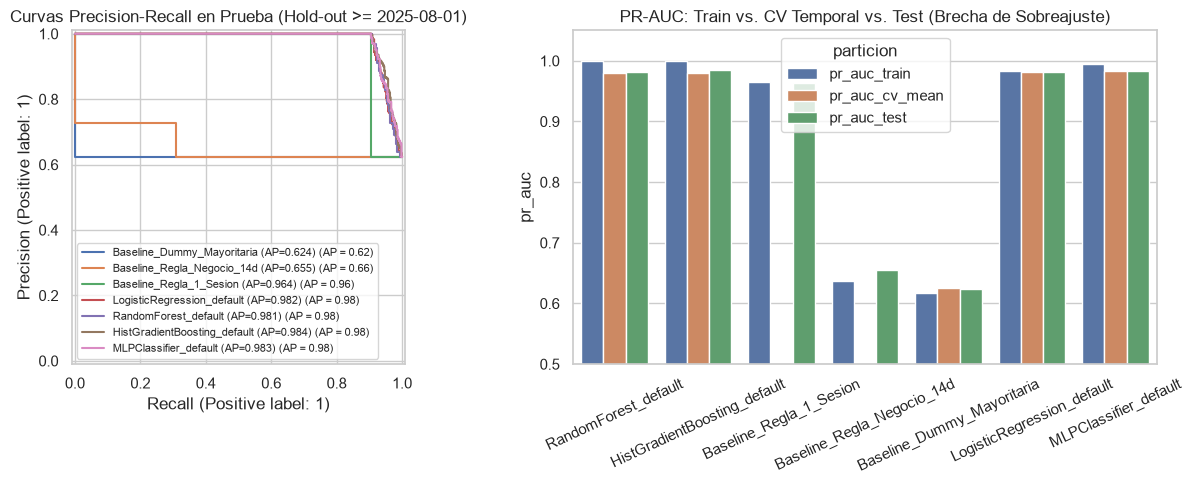

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Curvas Precision-Recall en Test (hold-out)
for r in resultados:
    y_score = r["_estimador"].predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_score,
        name=f"{r['modelo']} (AP={r['pr_auc_test']:.3f})",
        ax=axes[0],
    )
axes[0].set_title("Curvas Precision-Recall en Prueba (Hold-out >= 2025-08-01)")
axes[0].legend(loc="lower left", fontsize=8)

# 2. Comparación Train vs CV vs Test (Diagnóstico de sobreajuste)
df_plot = df_tabla.melt(
    id_vars=["modelo"],
    value_vars=["pr_auc_train", "pr_auc_cv_mean", "pr_auc_test"],
    var_name="particion",
    value_name="pr_auc",
)
sns.barplot(data=df_plot, x="modelo", y="pr_auc", hue="particion", ax=axes[1])
axes[1].set_title("PR-AUC: Train vs. CV Temporal vs. Test (Brecha de Sobreajuste)")
axes[1].set_ylim(0.5, 1.05)
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [5]:
experimentos_reg = [
    (
        "LogisticRegression_C100 (débil)",
        "Lineal_Regularizado",
        construir_pipeline(LogisticRegression(C=100.0, max_iter=1000, random_state=SEMILLA), escalar_numericas=True),
    ),
    (
        "LogisticRegression_C0.05 (fuerte)",
        "Lineal_Regularizado",
        construir_pipeline(LogisticRegression(C=0.05, max_iter=1000, random_state=SEMILLA), escalar_numericas=True),
    ),
    (
        "RandomForest_sin_poda (default)",
        "Bagging",
        construir_pipeline(RandomForestClassifier(random_state=SEMILLA), escalar_numericas=False),
    ),
    (
        "RandomForest_max_depth5 (podado)",
        "Bagging",
        construir_pipeline(RandomForestClassifier(max_depth=5, min_samples_leaf=10, random_state=SEMILLA), escalar_numericas=False),
    ),
    (
        "HistGB_default (l2=0.0)",
        "Boosting",
        construir_pipeline(HistGradientBoostingClassifier(random_state=SEMILLA), escalar_numericas=False),
    ),
    (
        "HistGB_regularizado (l2=5.0, depth=4)",
        "Boosting",
        construir_pipeline(HistGradientBoostingClassifier(max_depth=4, l2_regularization=5.0, min_samples_leaf=30, random_state=SEMILLA), escalar_numericas=False),
    ),
    (
        "MLP_alpha0.0001 (default)",
        "Red_Neuronal",
        construir_pipeline(MLPClassifier(alpha=0.0001, max_iter=500, random_state=SEMILLA), escalar_numericas=True),
    ),
    (
        "MLP_alpha1.0 (L2 fuerte)",
        "Red_Neuronal",
        construir_pipeline(MLPClassifier(alpha=1.0, max_iter=500, random_state=SEMILLA), escalar_numericas=True),
    ),
]

df_reg = pd.DataFrame([evaluar_modelo(n, f, p) for n, f, p in experimentos_reg])[
    ["modelo", "familia", "pr_auc_train", "pr_auc_cv_mean", "pr_auc_test", "brecha_train_test", "segundos"]
]
display(df_reg)

,modelo,familia,pr_auc_train,pr_auc_cv_mean,pr_auc_test,brecha_train_test,segundos
0,LogisticRegression_C100 (débil),Lineal_Regularizado,0.9855,0.9830,0.9823,0.0033,0.1023
1,LogisticRegression_C0.05 (fuerte),Lineal_Regularizado,0.9816,0.9804,0.9793,0.0023,0.0612
2,RandomForest_sin_poda (default),Bagging,1.0000,0.9797,0.9814,0.0185,0.4092
3,RandomForest_max_depth5 (podado),Bagging,0.9826,0.9794,0.9797,0.0029,0.3395
4,HistGB_default (l2=0.0),Boosting,0.9998,0.9806,0.9843,0.0155,0.4440
5,"HistGB_regularizado (l2=5.0, depth=4)",Boosting,0.9913,0.9820,0.9851,0.0062,0.1947
6,MLP_alpha0.0001 (default),Red_Neuronal,0.9944,0.9826,0.9833,0.0111,3.4228
7,MLP_alpha1.0 (L2 fuerte),Red_Neuronal,0.9853,0.9818,0.9826,0.0027,1.0829


## 4. Diagnóstico de Sobreajuste y Efecto de la Regularización

1. **Superación de las tres líneas base:**
   * En prueba (`test`), `Baseline_Dummy_Mayoritaria` alcanza `PR-AUC = 0.6235` y `Baseline_Regla_Negocio_14d` llega a `PR-AUC = 0.6551` (`F1 = 0.4332`, `Recall = 0.3087`), mientras que la regla estructural del EDA (`Baseline_Regla_1_Sesion`, basada en `sesiones_restantes == 1`) fija un piso exigente de **`PR-AUC = 0.9642`** (`F1 = 0.9501`).
   * Las cuatro familias tabulares superan por más de **+0.32 puntos** a las líneas base operativas y superan también a `Baseline_Regla_1_Sesion` (`0.9814` a `0.9843` en `test`), demostrando capacidad de discriminación temprana cuando aún faltan 2 o 3 sesiones[cite: 17].

2. **Diagnóstico de sobreajuste con hiperparámetros por defecto (`resultados_proyecto.csv`):**
   * **Mayor sobreajuste — Bagging y Boosting sin restricción:** `RandomForest_default` memoriza perfectamente el entrenamiento (`pr_auc_train = 1.0000` vs. `pr_auc_test = 0.9814`, `brecha = +0.0185`) y `HistGradientBoosting_default` alcanza `pr_auc_train = 0.9998` vs. `pr_auc_test = 0.9843` (`brecha = +0.0155`), aunque logra el mejor desempeño global en prueba (`PR-AUC = 0.9843`, `ROC-AUC = 0.9660`).
   * **Sobreajuste intermedio y alto costo — Red Neuronal:** `MLPClassifier_default` obtiene `pr_auc_train = 0.9944` vs. `pr_auc_test = 0.9833` (`brecha = +0.0111`), requiriendo `3.48 s` (casi 9 veces más lento que los ensamblajes).
   * **Menor sobreajuste — Lineal Regularizado:** `LogisticRegression_default` exhibe la brecha más pequeña (`pr_auc_train = 0.9837` vs. `pr_auc_test = 0.9816`, `brecha = +0.0021`) y el menor tiempo (`0.08 s`).

3. **Efecto comprobado de la regularización (`df_reg`):**
   * Al aplicar regularización en cada familia, la brecha entre entrenamiento y prueba se reduce drásticamente: en `RandomForest` baja de `0.0185` a `0.0029` (`max_depth=5`), en `MLPClassifier` de `0.0111` a `0.0027` (`alpha=1.0`), en `LogisticRegression` de `0.0033` a `0.0023` (`C=0.05`), y en `HistGradientBoosting` (`l2_regularization=5.0`, `max_depth=4`) la brecha cae de `0.0155` a `0.0062` mientras **sube `PR-AUC` en prueba de `0.9843` a `0.9851`** y reduce su tiempo a la mitad (`0.22 s`).